In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Customer 360 Project - Python Environment Ready!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Customer 360 Project - Python Environment Ready!
Pandas: 3.1.1
NumPy: 2.5.4


In [3]:
from google.cloud import bigquery

client = bigquery.Client(project="customer360-mktg")

print("BigQuery connection successful!")
print("Project:", client.project)

BigQuery connection successful!
Project: customer360-mktg


In [4]:
query = """
SELECT *
FROM `customer360-mktg.customer360.crm_customers_import`
LIMIT 10
"""

df_customers = client.query(query).to_dataframe()

display(df_customers)

C:\Users\kajal\AppData\Local\Programs\Python\Python312\Lib\site-packages\google\cloud\bigquery\table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,customer_id,email,first_name,last_name,signup_date,acquisition_channel,country
0,CUST004,customer004@example.com,Priya,Singh,2024-03-20,Email,India
1,CUST009,customer009@example.com,Aditya,Rao,2024-07-01,Email,India
2,CUST014,customer014@example.com,Diya,Chopra,2024-09-25,Email,India
3,CUST019,customer019@example.com,Dev,Sethi,2024-12-16,Email,India
4,CUST001,customer001@example.com,Aarav,Sharma,2024-01-15,Organic Search,India
5,CUST006,customer006@example.com,Ishita,Jain,2024-05-08,Organic Search,India
6,CUST011,customer011@example.com,Vihaan,Patel,2024-08-03,Organic Search,India
7,CUST016,customer016@example.com,Nisha,Yadav,2024-11-02,Organic Search,India
8,CUST002,customer002@example.com,Ananya,Verma,2024-02-10,Paid Search,India
9,CUST007,customer007@example.com,Kabir,Malhotra,2024-05-22,Paid Search,India


In [5]:
# Total customers
print("Total Customers:", df_customers["customer_id"].nunique())

# Customers by acquisition channel
print("\nCustomers by Acquisition Channel:")
print(df_customers["acquisition_channel"].value_counts())

# Customers by country
print("\nCustomers by Country:")
print(df_customers["country"].value_counts())

Total Customers: 10

Customers by Acquisition Channel:
acquisition_channel
Email             4
Organic Search    4
Paid Search       2
Name: count, dtype: int64

Customers by Country:
country
India    10
Name: count, dtype: int64


In [6]:
query = """
SELECT *
FROM `customer360-mktg.customer360.crm_customers_import`
ORDER BY customer_id
"""

df_customers = client.query(query).to_dataframe()

print("Total Customers:", len(df_customers))
display(df_customers)

C:\Users\kajal\AppData\Local\Programs\Python\Python312\Lib\site-packages\google\cloud\bigquery\table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


Total Customers: 20


,customer_id,email,first_name,last_name,signup_date,acquisition_channel,country
0,CUST001,customer001@example.com,Aarav,Sharma,2024-01-15,Organic Search,India
1,CUST002,customer002@example.com,Ananya,Verma,2024-02-10,Paid Search,India
2,CUST003,customer003@example.com,Rohan,Gupta,2024-03-05,Social Media,India
3,CUST004,customer004@example.com,Priya,Singh,2024-03-20,Email,India
4,CUST005,customer005@example.com,Arjun,Mehta,2024-04-12,Referral,India
5,CUST006,customer006@example.com,Ishita,Jain,2024-05-08,Organic Search,India
6,CUST007,customer007@example.com,Kabir,Malhotra,2024-05-22,Paid Search,India
7,CUST008,customer008@example.com,Meera,Kapoor,2024-06-14,Social Media,India
8,CUST009,customer009@example.com,Aditya,Rao,2024-07-01,Email,India
9,CUST010,customer010@example.com,Sanya,Bansal,2024-07-19,Referral,India


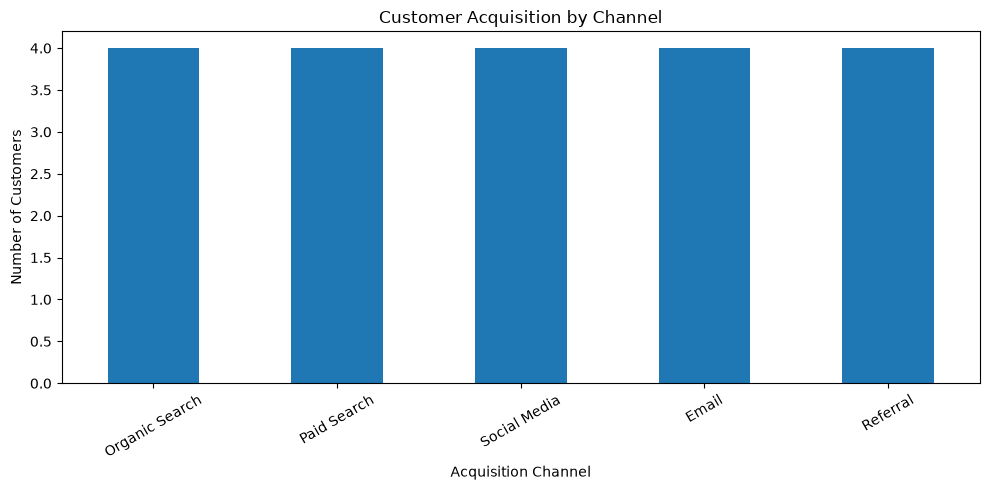

In [7]:
# Count customers by acquisition channel
channel_counts = df_customers["acquisition_channel"].value_counts()

# Create bar chart
plt.figure(figsize=(10, 5))
channel_counts.plot(kind="bar")

plt.title("Customer Acquisition by Channel")
plt.xlabel("Acquisition Channel")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [8]:
query = """
SELECT
    order_id,
    customer_id,
    order_date,
    order_amount,
    order_status,
    payment_method
FROM `customer360-mktg.customer360.crm_orders`
ORDER BY order_date
"""

df_orders = client.query(query).to_dataframe()

print("Total Orders:", len(df_orders))
print("Total Revenue: ₹", df_orders["order_amount"].sum())

display(df_orders.head(10))


C:\Users\kajal\AppData\Local\Programs\Python\Python312\Lib\site-packages\google\cloud\bigquery\table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


Total Orders: 40
Total Revenue: ₹ 908000.000000000


,order_id,customer_id,order_date,order_amount,order_status,payment_method
0,ORD001,CUST001,2024-02-14,12474.000000000,Completed,Credit Card
1,ORD003,CUST002,2024-03-11,43130.000000000,Completed,Credit Card
2,ORD002,CUST001,2024-03-15,24815.000000000,Completed,Debit Card
3,ORD005,CUST003,2024-04-04,1715.000000000,Completed,Credit Card
4,ORD004,CUST002,2024-04-10,4471.000000000,Completed,Debit Card
5,ORD007,CUST004,2024-04-19,41009.000000000,Completed,Credit Card
6,ORD006,CUST003,2024-05-04,2070.000000000,Completed,Debit Card
7,ORD009,CUST005,2024-05-12,15760.000000000,Completed,Credit Card
8,ORD008,CUST004,2024-05-19,24644.000000000,Completed,Debit Card
9,ORD011,CUST006,2024-06-07,19165.000000000,Completed,Credit Card


In [9]:
# Convert order_date to datetime
df_orders["order_date"] = pd.to_datetime(df_orders["order_date"])

# Extract month
df_orders["month"] = df_orders["order_date"].dt.to_period("M").astype(str)

# Calculate monthly revenue
monthly_revenue = (
    df_orders.groupby("month")["order_amount"]
    .sum()
    .reset_index()
)

print("Monthly Revenue Analysis:")
display(monthly_revenue)

Monthly Revenue Analysis:


,month,order_amount
0,2024-02,12474.000000000
1,2024-03,67945.000000000
2,2024-04,47195.000000000
3,2024-05,42474.000000000
4,2024-06,34313.000000000
5,2024-07,66762.000000000
6,2024-08,69038.000000000
7,2024-09,78351.000000000
8,2024-10,114611.000000000
9,2024-11,76821.000000000


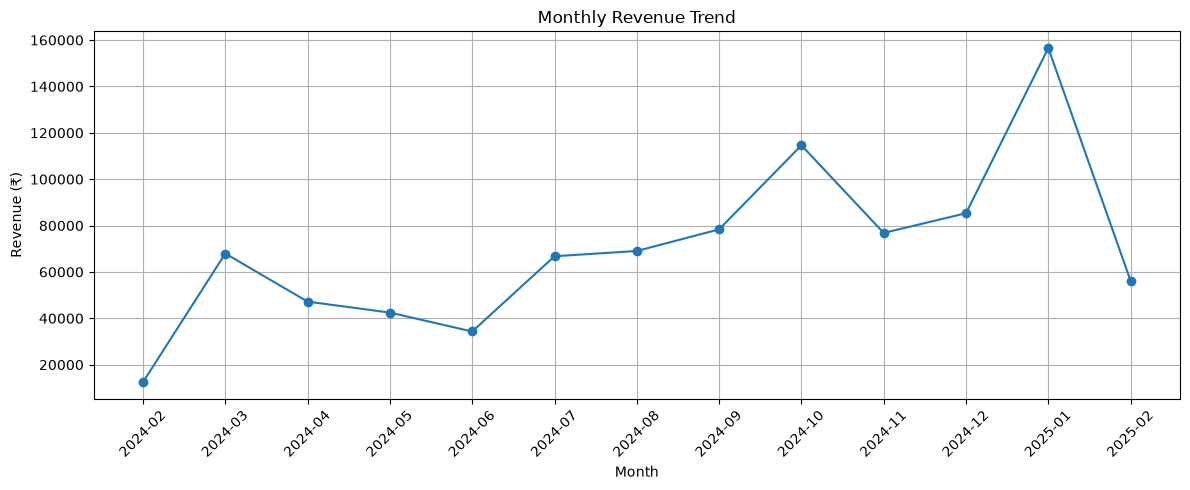

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue["month"],
    monthly_revenue["order_amount"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [11]:
# Calculate revenue generated by each customer
customer_revenue = (
    df_orders.groupby("customer_id")
    .agg(
        total_orders=("order_id", "count"),
        total_revenue=("order_amount", "sum")
    )
    .reset_index()
)

# Sort customers by revenue
customer_revenue = customer_revenue.sort_values(
    by="total_revenue",
    ascending=False
)

print("Top 10 Customers by Revenue:")
display(customer_revenue.head(10))

Top 10 Customers by Revenue:


,customer_id,total_orders,total_revenue
15,CUST016,2,82948.000000000
12,CUST013,2,69013.000000000
3,CUST004,2,65653.000000000
11,CUST012,2,60295.000000000
16,CUST017,2,57265.000000000
19,CUST020,2,57211.000000000
13,CUST014,2,53479.000000000
14,CUST015,2,48450.000000000
5,CUST006,2,47783.000000000
1,CUST002,2,47601.000000000


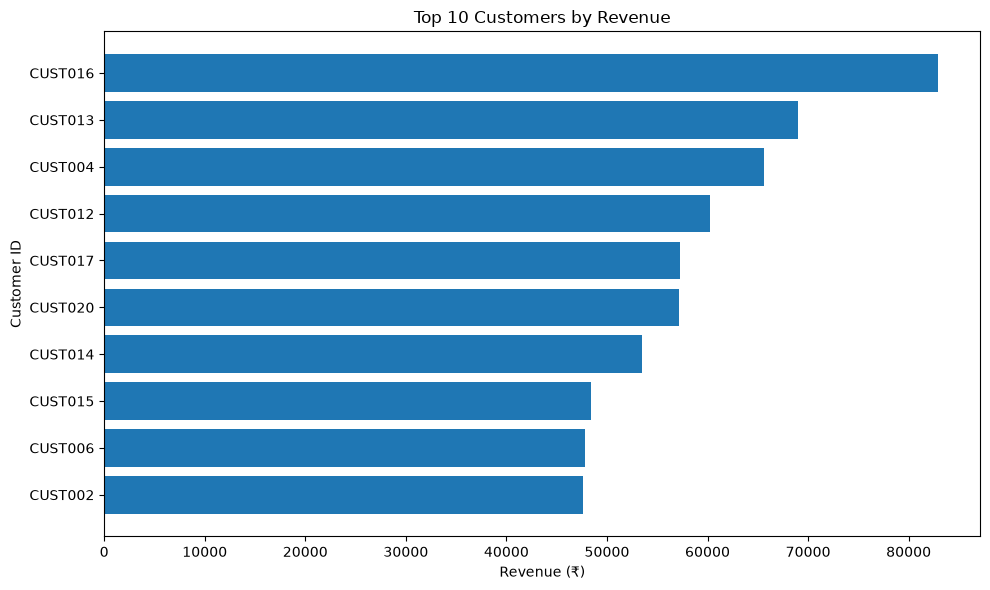

In [12]:
top_10 = customer_revenue.head(10).sort_values("total_revenue")

plt.figure(figsize=(10, 6))

plt.barh(
    top_10["customer_id"],
    top_10["total_revenue"]
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue (₹)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

In [13]:
# Convert order date to datetime
df_orders["order_date"] = pd.to_datetime(df_orders["order_date"])

# Set analysis date after the latest order
analysis_date = df_orders["order_date"].max() + pd.Timedelta(days=1)

# Calculate RFM metrics
rfm = df_orders.groupby("customer_id").agg(
    Recency=("order_date", lambda x: (analysis_date - x.max()).days),
    Frequency=("order_id", "nunique"),
    Monetary=("order_amount", "sum")
).reset_index()

# Sort by monetary value
rfm = rfm.sort_values("Monetary", ascending=False)

print("Customer RFM Analysis:")
display(rfm)

Customer RFM Analysis:


,customer_id,Recency,Frequency,Monetary
15,CUST016,57,2,82948.000000000
12,CUST013,111,2,69013.000000000
3,CUST004,284,2,65653.000000000
11,CUST012,134,2,60295.000000000
16,CUST017,41,2,57265.000000000
19,CUST020,1,2,57211.000000000
13,CUST014,95,2,53479.000000000
14,CUST015,79,2,48450.000000000
5,CUST006,235,2,47783.000000000
1,CUST002,323,2,47601.000000000


In [14]:
# Recency: lower days = better score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: higher orders = better score
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: higher revenue = better score
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combined RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

display(rfm.head(10))

,customer_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
15,CUST016,57,2,82948.000000000,4,1,5,415
12,CUST013,111,2,69013.000000000,4,1,5,415
3,CUST004,284,2,65653.000000000,1,1,5,115
11,CUST012,134,2,60295.000000000,3,1,5,315
16,CUST017,41,2,57265.000000000,5,2,4,524
19,CUST020,1,2,57211.000000000,5,2,4,524
13,CUST014,95,2,53479.000000000,4,2,4,424
14,CUST015,79,2,48450.000000000,4,2,4,424
5,CUST006,235,2,47783.000000000,2,3,3,233
1,CUST002,323,2,47601.000000000,1,3,3,133


In [15]:
def classify_customer(row):
    if row["R_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"
    elif row["R_Score"] >= 3 and row["M_Score"] >= 4:
        return "High Value"
    elif row["R_Score"] <= 2 and row["M_Score"] >= 3:
        return "At Risk"
    elif row["R_Score"] <= 2:
        return "Needs Attention"
    else:
        return "Regular"

rfm["Customer_Segment"] = rfm.apply(
    classify_customer, axis=1
)

print("Customer Segmentation Results:")
display(rfm[[
    "customer_id",
    "Recency",
    "Frequency",
    "Monetary",
    "R_Score",
    "M_Score",
    "Customer_Segment"
]])

Customer Segmentation Results:


,customer_id,Recency,Frequency,Monetary,R_Score,M_Score,Customer_Segment
15,CUST016,57,2,82948.000000000,4,5,Champions
12,CUST013,111,2,69013.000000000,4,5,Champions
3,CUST004,284,2,65653.000000000,1,5,At Risk
11,CUST012,134,2,60295.000000000,3,5,High Value
16,CUST017,41,2,57265.000000000,5,4,Champions
19,CUST020,1,2,57211.000000000,5,4,Champions
13,CUST014,95,2,53479.000000000,4,4,Champions
14,CUST015,79,2,48450.000000000,4,4,Champions
5,CUST006,235,2,47783.000000000,2,3,At Risk
1,CUST002,323,2,47601.000000000,1,3,At Risk


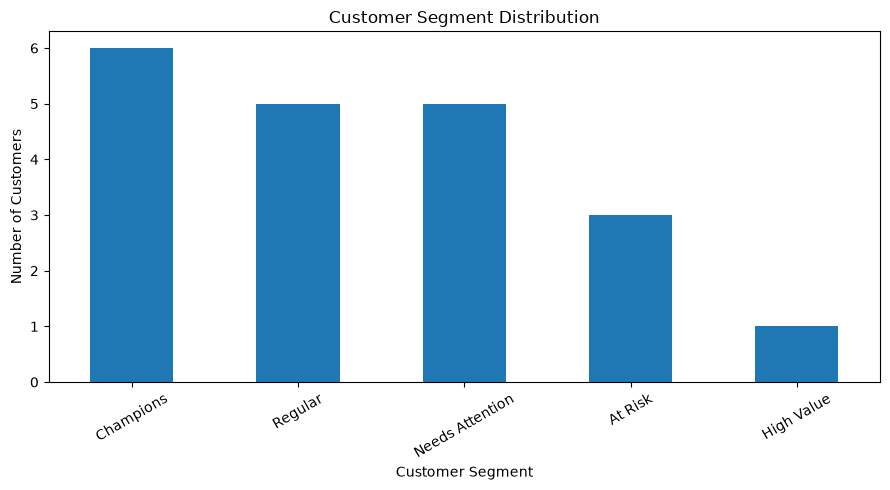

In [16]:
segment_counts = rfm["Customer_Segment"].value_counts()

plt.figure(figsize=(9, 5))

segment_counts.plot(kind="bar")

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [17]:
query = """
SELECT *
FROM `customer360-mktg.customer360.vw_customer_rfm`
ORDER BY customer_id
"""

df_rfm_original = client.query(query).to_dataframe()

display(df_rfm_original)

C:\Users\kajal\AppData\Local\Programs\Python\Python312\Lib\site-packages\google\cloud\bigquery\table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,customer_id,recency,frequency,monetary,recency_score,frequency_score,monetary_score,rfm_segment,customer_segment
0,CUST001,349,2,37289.000000000,1,1,2,112,At Risk
1,CUST002,323,2,47601.000000000,1,1,3,113,At Risk
2,CUST003,299,2,3785.000000000,1,1,1,111,At Risk
3,CUST004,284,2,65653.000000000,1,1,5,115,At Risk
4,CUST005,261,2,17446.000000000,2,2,1,221,At Risk
5,CUST006,235,2,47783.000000000,2,2,3,223,At Risk
6,CUST007,221,2,35867.000000000,2,2,2,222,At Risk
7,CUST008,198,2,28459.000000000,2,2,1,221,At Risk
8,CUST009,181,2,38695.000000000,3,3,2,332,Regular Customers
9,CUST010,163,2,36838.000000000,3,3,2,332,Regular Customers


In [18]:
# Compare customer segment counts
bigquery_segments = (
    df_rfm_original["customer_segment"]
    .value_counts()
    .sort_index()
)

print("Customer Segmentation from BigQuery:")
display(bigquery_segments)

# Check total customers
print("Total Customers:", len(df_rfm_original))

# Check segment totals
print(
    "Segment validation:",
    bigquery_segments.sum() == len(df_rfm_original)
)

Customer Segmentation from BigQuery:


customer_segment
At Risk              8
Champions            6
Loyal Customers      2
Regular Customers    4
Name: count, dtype: int64

Total Customers: 20
Segment validation: True


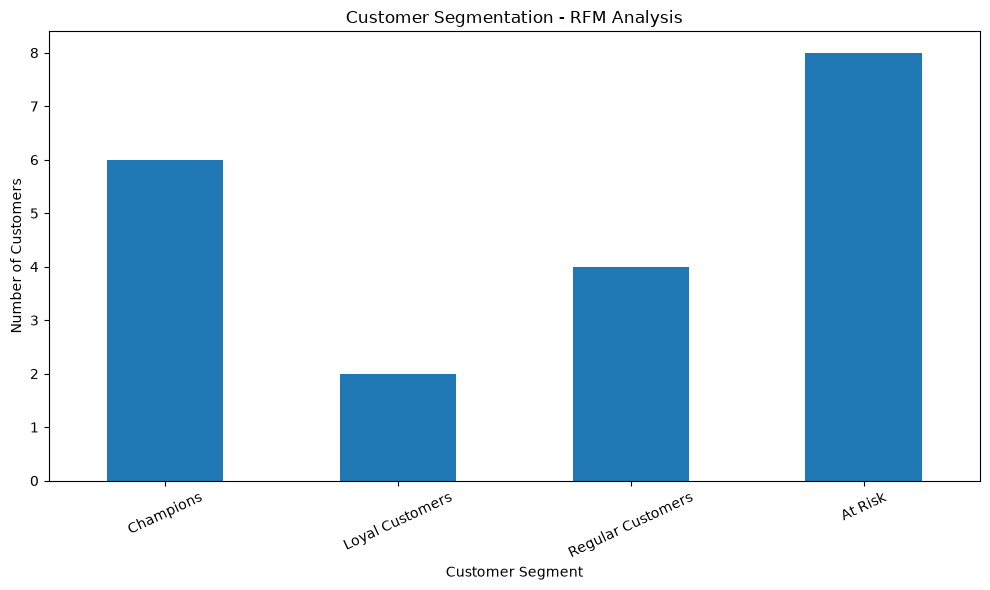

In [19]:
segment_counts = (
    df_rfm_original["customer_segment"]
    .value_counts()
    .reindex([
        "Champions",
        "Loyal Customers",
        "Regular Customers",
        "At Risk"
    ])
)

plt.figure(figsize=(10, 6))

segment_counts.plot(kind="bar")

plt.title("Customer Segmentation - RFM Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [20]:
query = """
SELECT *
FROM `customer360-mktg.customer360.crm_marketing_spend`
ORDER BY channel
"""

df_marketing = client.query(query).to_dataframe()

print("Total Marketing Records:", len(df_marketing))
display(df_marketing)

C:\Users\kajal\AppData\Local\Programs\Python\Python312\Lib\site-packages\google\cloud\bigquery\table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


Total Marketing Records: 10


,spend_id,campaign_name,channel,spend_date,spend_amount,impressions,clicks,conversions
0,SP006,Festival Discount Campaign,Display Ads,2025-11-15,15000.000000000,70000,2100,90
1,SP004,Email Retention Campaign,Email,2025-02-15,5000.000000000,20000,4000,180
2,SP007,Customer Loyalty Program,Email,2025-05-15,7000.000000000,15000,3500,150
3,SP009,Winter Sale Campaign,Paid Search,2025-12-15,18000.000000000,100000,5000,250
4,SP003,Google Search Promotion,Paid Search,2025-02-15,10000.000000000,45000,2200,100
5,SP001,Summer Sale 2025,Paid Search,2025-04-15,12000.000000000,50000,2500,120
6,SP010,Referral Marketing Campaign,Referral,2025-07-15,4000.000000000,10000,1800,100
7,SP002,Diwali Shopping Campaign,Social Media,2025-10-15,18000.000000000,80000,3200,150
8,SP005,Instagram Brand Awareness,Social Media,2025-03-15,12000.000000000,65000,2800,110
9,SP008,YouTube Video Promotion,Video Ads,2025-06-15,14000.000000000,90000,4500,130


In [21]:
# Aggregate marketing performance by channel
channel_performance = (
    df_marketing.groupby("channel")
    .agg(
        total_spend=("spend_amount", "sum"),
        impressions=("impressions", "sum"),
        clicks=("clicks", "sum"),
        conversions=("conversions", "sum")
    )
    .reset_index()
)

# Calculate marketing KPIs
channel_performance["CTR (%)"] = (
    channel_performance["clicks"] /
    channel_performance["impressions"] * 100
)

channel_performance["Conversion Rate (%)"] = (
    channel_performance["conversions"] /
    channel_performance["clicks"] * 100
)

channel_performance["CPC"] = (
    channel_performance["total_spend"] /
    channel_performance["clicks"]
)

channel_performance["Cost per Conversion"] = (
    channel_performance["total_spend"] /
    channel_performance["conversions"]
)

# Display results
display(channel_performance.round(2))

,channel,total_spend,impressions,clicks,conversions,CTR (%),Conversion Rate (%),CPC,Cost per Conversion
0,Display Ads,15000.000000000,70000,2100,90,3.0,4.29,7.142857142857142857142857143,166.6666666666666666666666667
1,Email,12000.000000000,35000,7500,330,21.43,4.4,1.600000000,36.36363636363636363636363636
2,Paid Search,40000.000000000,195000,9700,470,4.97,4.85,4.123711340206185567010309278,85.10638297872340425531914894
3,Referral,4000.000000000,10000,1800,100,18.0,5.56,2.222222222222222222222222222,40.000000000
4,Social Media,30000.000000000,145000,6000,260,4.14,4.33,5.000000000,115.3846153846153846153846154
5,Video Ads,14000.000000000,90000,4500,130,5.0,2.89,3.111111111111111111111111111,107.6923076923076923076923077


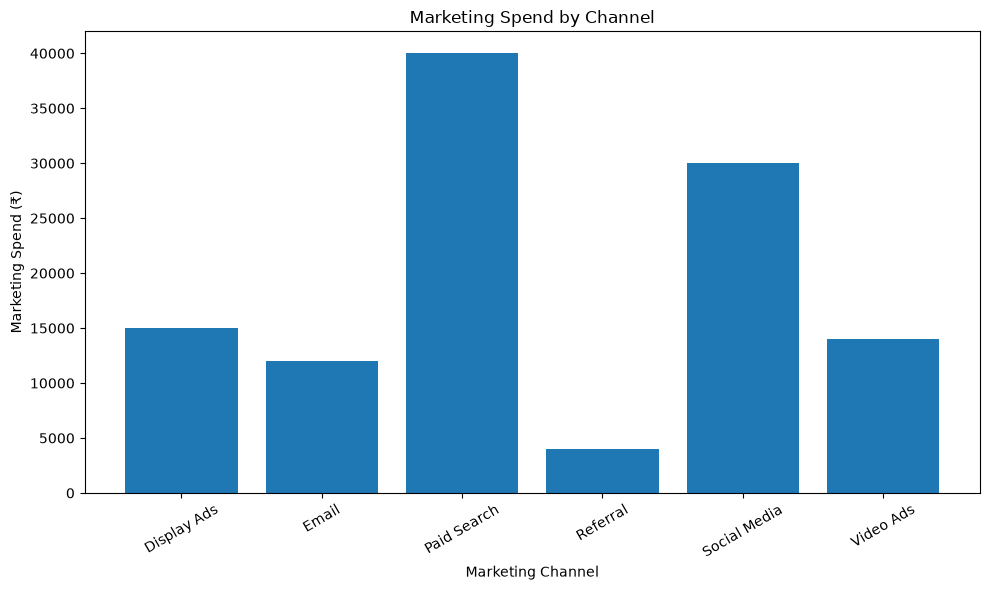

In [22]:
plt.figure(figsize=(10, 6))

plt.bar(
    channel_performance["channel"],
    channel_performance["total_spend"]
)

plt.title("Marketing Spend by Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Marketing Spend (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

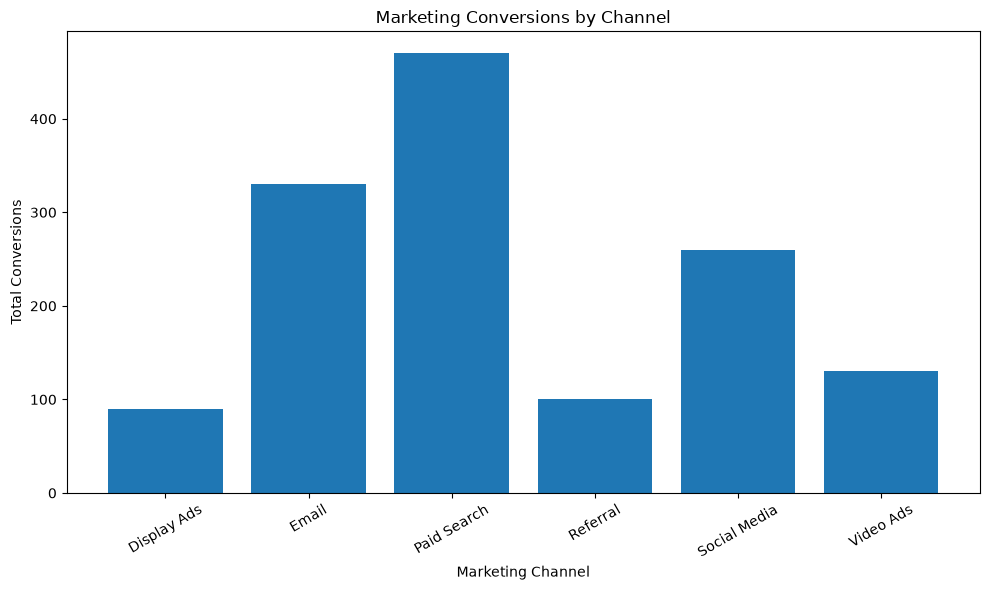

In [23]:
plt.figure(figsize=(10, 6))

plt.bar(
    channel_performance["channel"],
    channel_performance["conversions"]
)

plt.title("Marketing Conversions by Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Total Conversions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [24]:
campaign_performance = (
    df_marketing.groupby("campaign_name")
    .agg(
        total_spend=("spend_amount", "sum"),
        impressions=("impressions", "sum"),
        clicks=("clicks", "sum"),
        conversions=("conversions", "sum")
    )
    .reset_index()
)

campaign_performance["CTR (%)"] = (
    campaign_performance["clicks"] /
    campaign_performance["impressions"] * 100
)

campaign_performance["Conversion Rate (%)"] = (
    campaign_performance["conversions"] /
    campaign_performance["clicks"] * 100
)

campaign_performance["Cost per Conversion"] = (
    campaign_performance["total_spend"] /
    campaign_performance["conversions"]
)

campaign_performance = campaign_performance.sort_values(
    "conversions", ascending=False
)

display(campaign_performance.round(2))

,campaign_name,total_spend,impressions,clicks,conversions,CTR (%),Conversion Rate (%),Cost per Conversion
8,Winter Sale Campaign,18000.000000000,100000,5000,250,5.0,5.0,72.000000000
2,Email Retention Campaign,5000.000000000,20000,4000,180,20.0,4.5,27.77777777777777777777777778
1,Diwali Shopping Campaign,18000.000000000,80000,3200,150,4.0,4.69,120.000000000
0,Customer Loyalty Program,7000.000000000,15000,3500,150,23.33,4.29,46.66666666666666666666666667
9,YouTube Video Promotion,14000.000000000,90000,4500,130,5.0,2.89,107.6923076923076923076923077
7,Summer Sale 2025,12000.000000000,50000,2500,120,5.0,4.8,100.000000000
5,Instagram Brand Awareness,12000.000000000,65000,2800,110,4.31,3.93,109.0909090909090909090909091
4,Google Search Promotion,10000.000000000,45000,2200,100,4.89,4.55,100.000000000
6,Referral Marketing Campaign,4000.000000000,10000,1800,100,18.0,5.56,40.000000000
3,Festival Discount Campaign,15000.000000000,70000,2100,90,3.0,4.29,166.6666666666666666666666667


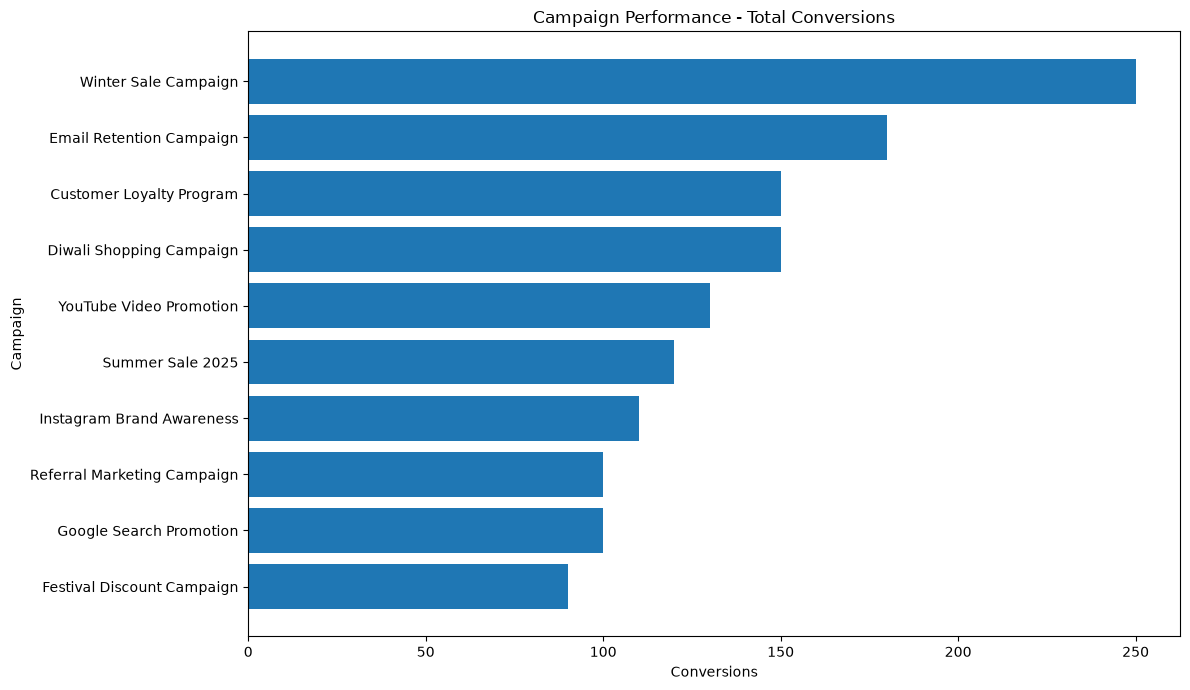

In [25]:
top_campaigns = campaign_performance.sort_values(
    "conversions", ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_campaigns["campaign_name"],
    top_campaigns["conversions"]
)

plt.title("Campaign Performance - Total Conversions")
plt.xlabel("Conversions")
plt.ylabel("Campaign")
plt.tight_layout()
plt.show()

In [26]:
query = """
SELECT *
FROM `customer360-mktg.customer360.attribution_model_results`
ORDER BY attribution_model, channel
"""

df_attribution = client.query(query).to_dataframe()

print("Total Attribution Records:", len(df_attribution))
display(df_attribution)

BadRequest: 400 Unrecognized name: channel at [4:29]; reason: invalidQuery, location: query, message: Unrecognized name: channel at [4:29]

Location: asia-south1
Job ID: 5b11e0a7-0a55-4a57-8b60-b7cf28b2ee52


In [27]:
query = """
SELECT
    column_name,
    data_type
FROM `customer360-mktg.customer360.INFORMATION_SCHEMA.COLUMNS`
WHERE table_name = 'attribution_model_results'
ORDER BY ordinal_position
"""

df_columns = client.query(query).to_dataframe()

display(df_columns)

C:\Users\kajal\AppData\Local\Programs\Python\Python312\Lib\site-packages\google\cloud\bigquery\table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,column_name,data_type
0,attribution_model,STRING
1,source,STRING
2,campaign,STRING
3,orders,INT64
4,attributed_revenue,FLOAT64


In [28]:
query = """
SELECT *
FROM `customer360-mktg.customer360.attribution_model_results`
ORDER BY attribution_model, source
"""

df_attribution = client.query(query).to_dataframe()

print("Total Attribution Records:", len(df_attribution))
display(df_attribution)

C:\Users\kajal\AppData\Local\Programs\Python\Python312\Lib\site-packages\google\cloud\bigquery\table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


Total Attribution Records: 24


,attribution_model,source,campaign,orders,attributed_revenue
0,First Touch,Email,Campaign_1,1,17067.00
1,First Touch,Paid Search,Campaign_1,1,40010.00
2,First Touch,Referral,Campaign_1,1,42216.00
3,First Touch,Social Media,Campaign_1,1,14287.00
4,Last Touch,Email,Campaign_2,1,17067.00
5,Last Touch,Paid Search,Campaign_2,1,40010.00
6,Last Touch,Referral,Campaign_2,1,42216.00
7,Last Touch,Social Media,Campaign_2,1,14287.00
8,Linear,Email,Campaign_1,1,8533.50
9,Linear,Email,Campaign_2,1,8533.50


In [29]:
attribution_summary = (
    df_attribution.groupby("attribution_model")
    .agg(
        total_orders=("orders", "sum"),
        attributed_revenue=("attributed_revenue", "sum")
    )
    .reset_index()
)

print("Attribution Model Comparison:")
display(attribution_summary.round(2))

Attribution Model Comparison:


,attribution_model,total_orders,attributed_revenue
0,First Touch,4,113580.0
1,Last Touch,4,113580.0
2,Linear,8,113580.0
3,Time Decay,8,113580.0


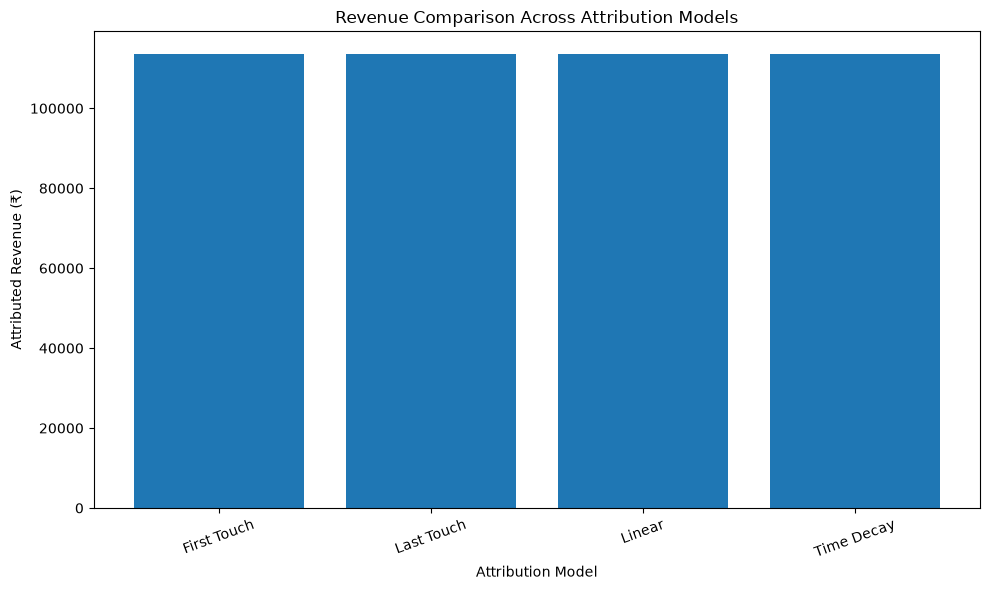

In [30]:
plt.figure(figsize=(10, 6))

plt.bar(
    attribution_summary["attribution_model"],
    attribution_summary["attributed_revenue"]
)

plt.title("Revenue Comparison Across Attribution Models")
plt.xlabel("Attribution Model")
plt.ylabel("Attributed Revenue (₹)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [31]:
source_attribution = (
    df_attribution.groupby(["attribution_model", "source"])
    .agg(
        attributed_revenue=("attributed_revenue", "sum"),
        orders=("orders", "sum")
    )
    .reset_index()
)

print("Revenue Attribution by Marketing Source:")
display(source_attribution.round(2))

Revenue Attribution by Marketing Source:


,attribution_model,source,attributed_revenue,orders
0,First Touch,Email,17067.0,1
1,First Touch,Paid Search,40010.0,1
2,First Touch,Referral,42216.0,1
3,First Touch,Social Media,14287.0,1
4,Last Touch,Email,17067.0,1
5,Last Touch,Paid Search,40010.0,1
6,Last Touch,Referral,42216.0,1
7,Last Touch,Social Media,14287.0,1
8,Linear,Email,17067.0,2
9,Linear,Paid Search,40010.0,2


In [32]:
# Aggregate marketing spend by channel
channel_spend = (
    df_marketing.groupby("channel")["spend_amount"]
    .sum()
    .reset_index()
)

# Match marketing source with channel
roas_analysis = source_attribution.merge(
    channel_spend,
    left_on="source",
    right_on="channel",
    how="left"
)

# Calculate ROAS
roas_analysis["ROAS"] = (
    roas_analysis["attributed_revenue"] /
    roas_analysis["spend_amount"]
)

print("ROAS by Attribution Model and Source:")
display(
    roas_analysis[
        ["attribution_model", "source",
         "attributed_revenue", "spend_amount", "ROAS"]
    ].round(2)
)

TypeError: unsupported operand type(s) for /: 'float' and 'decimal.Decimal'

In [33]:
# Convert both columns to numeric float values
roas_analysis["attributed_revenue"] = pd.to_numeric(
    roas_analysis["attributed_revenue"]
).astype(float)

roas_analysis["spend_amount"] = pd.to_numeric(
    roas_analysis["spend_amount"]
).astype(float)

# Calculate ROAS
roas_analysis["ROAS"] = (
    roas_analysis["attributed_revenue"] /
    roas_analysis["spend_amount"]
)

print("ROAS Calculation Successful!")
display(
    roas_analysis[
        ["attribution_model", "source",
         "attributed_revenue", "spend_amount", "ROAS"]
    ].round(2)
)

ROAS Calculation Successful!


,attribution_model,source,attributed_revenue,spend_amount,ROAS
0,First Touch,Email,17067.0,12000.0,1.42
1,First Touch,Paid Search,40010.0,40000.0,1.00
2,First Touch,Referral,42216.0,4000.0,10.55
3,First Touch,Social Media,14287.0,30000.0,0.48
4,Last Touch,Email,17067.0,12000.0,1.42
5,Last Touch,Paid Search,40010.0,40000.0,1.00
6,Last Touch,Referral,42216.0,4000.0,10.55
7,Last Touch,Social Media,14287.0,30000.0,0.48
8,Linear,Email,17067.0,12000.0,1.42
9,Linear,Paid Search,40010.0,40000.0,1.00


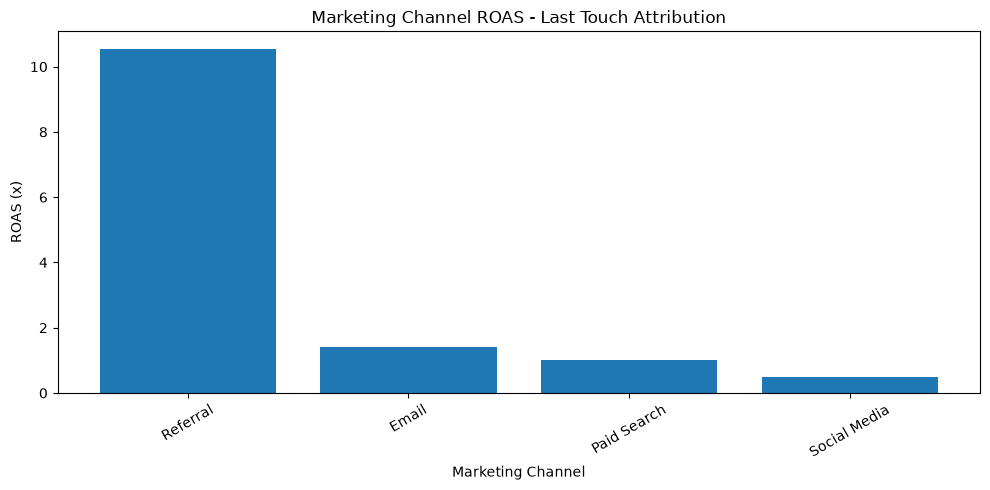

In [34]:
import matplotlib.pyplot as plt

roas_chart = (
    roas_analysis[
        roas_analysis["attribution_model"] == "Last Touch"
    ]
    .sort_values("ROAS", ascending=False)
)

plt.figure(figsize=(10, 5))

plt.bar(
    roas_chart["source"],
    roas_chart["ROAS"]
)

plt.title("Marketing Channel ROAS - Last Touch Attribution")
plt.xlabel("Marketing Channel")
plt.ylabel("ROAS (x)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

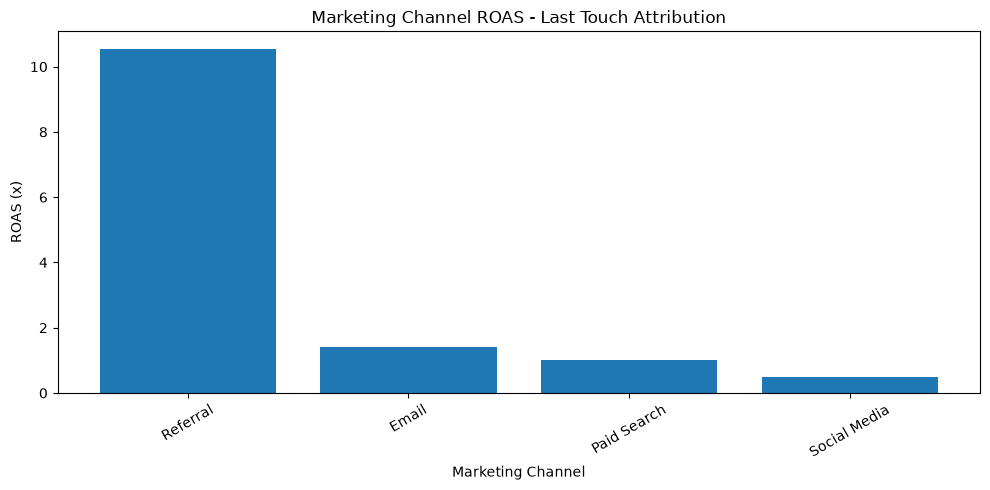

In [35]:
plt.figure(figsize=(10, 5))
plt.bar(roas_chart["source"], roas_chart["ROAS"])

plt.title("Marketing Channel ROAS - Last Touch Attribution")
plt.xlabel("Marketing Channel")
plt.ylabel("ROAS (x)")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    "marketing_channel_roas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
segment_summary = (
    df_rfm_original["customer_segment"]
    .value_counts()
    .reset_index()
)

segment_summary.columns = ["Customer Segment", "Customer Count"]

display(segment_summary)

,Customer Segment,Customer Count
0,At Risk,8
1,Champions,6
2,Regular Customers,4
3,Loyal Customers,2


In [37]:
high_value_customers = (
    df_rfm_original[
        df_rfm_original["customer_segment"] == "Champions"
    ]
    [["customer_id", "recency", "frequency", "monetary",
      "customer_segment"]]
    .sort_values("monetary", ascending=False)
)

display(high_value_customers)

,customer_id,recency,frequency,monetary,customer_segment
15,CUST016,57,2,82948.000000000,Champions
12,CUST013,111,2,69013.000000000,Champions
16,CUST017,41,2,57265.000000000,Champions
19,CUST020,1,2,57211.000000000,Champions
13,CUST014,95,2,53479.000000000,Champions
14,CUST015,79,2,48450.000000000,Champions


In [38]:
at_risk_customers = (
    df_rfm_original[
        df_rfm_original["customer_segment"] == "At Risk"
    ]
    [["customer_id", "recency", "frequency", "monetary",
      "customer_segment"]]
    .sort_values("recency", ascending=False)
)

display(at_risk_customers)

,customer_id,recency,frequency,monetary,customer_segment
0,CUST001,349,2,37289.000000000,At Risk
1,CUST002,323,2,47601.000000000,At Risk
2,CUST003,299,2,3785.000000000,At Risk
3,CUST004,284,2,65653.000000000,At Risk
4,CUST005,261,2,17446.000000000,At Risk
5,CUST006,235,2,47783.000000000,At Risk
6,CUST007,221,2,35867.000000000,At Risk
7,CUST008,198,2,28459.000000000,At Risk


In [39]:
at_risk_summary = {
    "At Risk Customers": len(at_risk_customers),
    "Total At Risk Revenue": at_risk_customers["monetary"].sum(),
    "Average Customer Revenue": at_risk_customers["monetary"].mean(),
    "Average Recency (Days)": at_risk_customers["recency"].mean()
}

display(pd.DataFrame(
    list(at_risk_summary.items()),
    columns=["Metric", "Value"]
))

,Metric,Value
0,At Risk Customers,8
1,Total At Risk Revenue,283883.000000000
2,Average Customer Revenue,35485.375
3,Average Recency (Days),271.25


In [40]:
segment_revenue = (
    df_rfm_original
    .groupby("customer_segment")
    .agg(
        customers=("customer_id", "count"),
        total_revenue=("monetary", "sum"),
        average_revenue=("monetary", "mean")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

segment_revenue["revenue_share_pct"] = (
    segment_revenue["total_revenue"]
    / segment_revenue["total_revenue"].sum() * 100
)

display(segment_revenue.round(2))

,customer_segment,customers,total_revenue,average_revenue,revenue_share_pct
1,Champions,6,368366.000000000,61394.333333,40.56894273127753303964757709
0,At Risk,8,283883.000000000,35485.375,31.26464757709251101321585903
3,Regular Customers,4,183251.000000000,45812.75,20.18182819383259911894273128
2,Loyal Customers,2,72500.000000000,36250.0,7.984581497797356828193832599


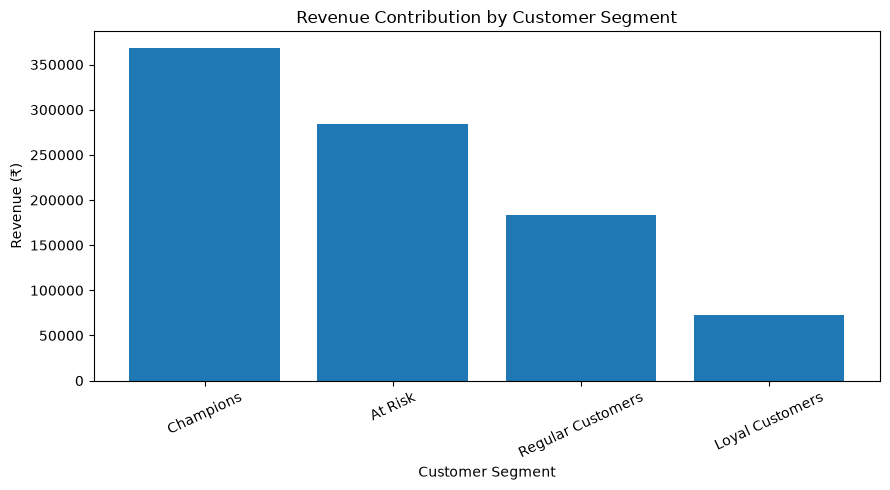

In [41]:
plt.figure(figsize=(9, 5))

plt.bar(
    segment_revenue["customer_segment"],
    segment_revenue["total_revenue"]
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

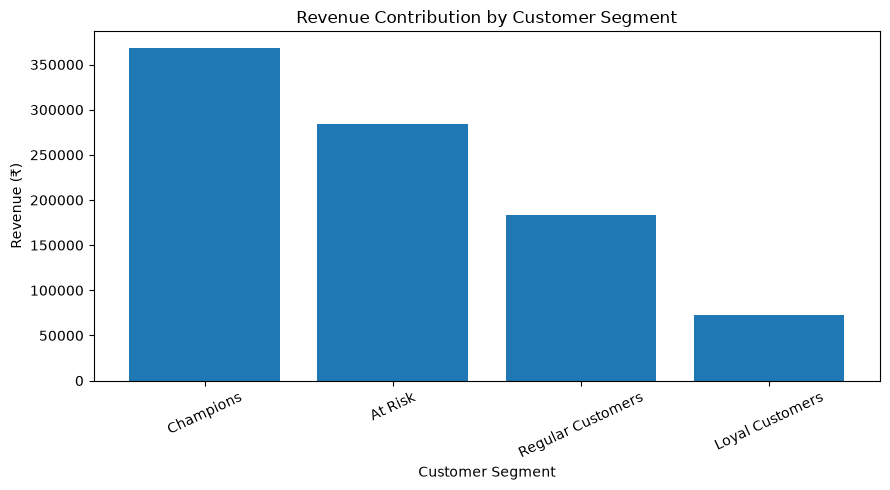

In [42]:
plt.figure(figsize=(9, 5))

plt.bar(
    segment_revenue["customer_segment"],
    segment_revenue["total_revenue"]
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig(
    "customer_segment_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [43]:
business_insights = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Total Orders",
        "Total Revenue",
        "Champions Customers",
        "At Risk Customers",
        "At Risk Historical Revenue",
        "Highest Revenue Segment",
        "Best ROAS Channel"
    ],
    "Result": [
        20,
        40,
        "₹9,08,000",
        6,
        8,
        "₹2,83,883",
        "Champions",
        "Referral (10.55x)"
    ]
})

display(business_insights)


,Metric,Result
0,Total Customers,20
1,Total Orders,40
2,Total Revenue,"₹9,08,000"
3,Champions Customers,6
4,At Risk Customers,8
5,At Risk Historical Revenue,"₹2,83,883"
6,Highest Revenue Segment,Champions
7,Best ROAS Channel,Referral (10.55x)


In [44]:
business_insights.to_csv(
    "customer360_business_insights.csv",
    index=False
)

print("Business insights CSV saved successfully!")

Business insights CSV saved successfully!
